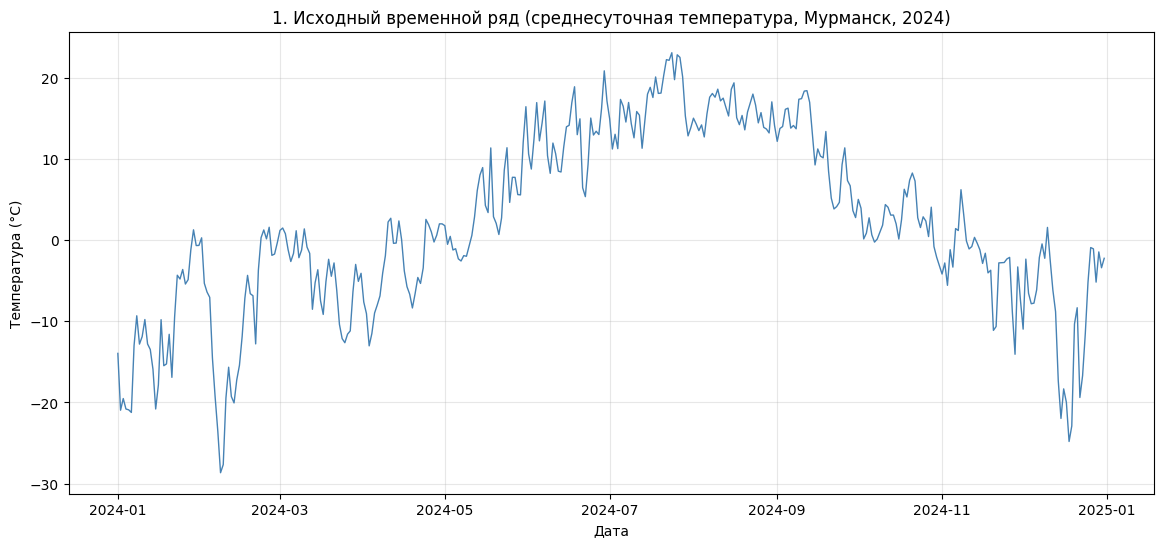

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import linregress


plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


df = pd.read_csv('../files/time_series_murmansk_2024.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.set_index('datetime')


ts = df['temperature_c'].resample('D').mean().dropna()


plt.figure()
plt.plot(ts.index, ts.values, color='steelblue', linewidth=1)
plt.title("1. Исходный временной ряд (среднесуточная температура, Мурманск, 2024)")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.show()

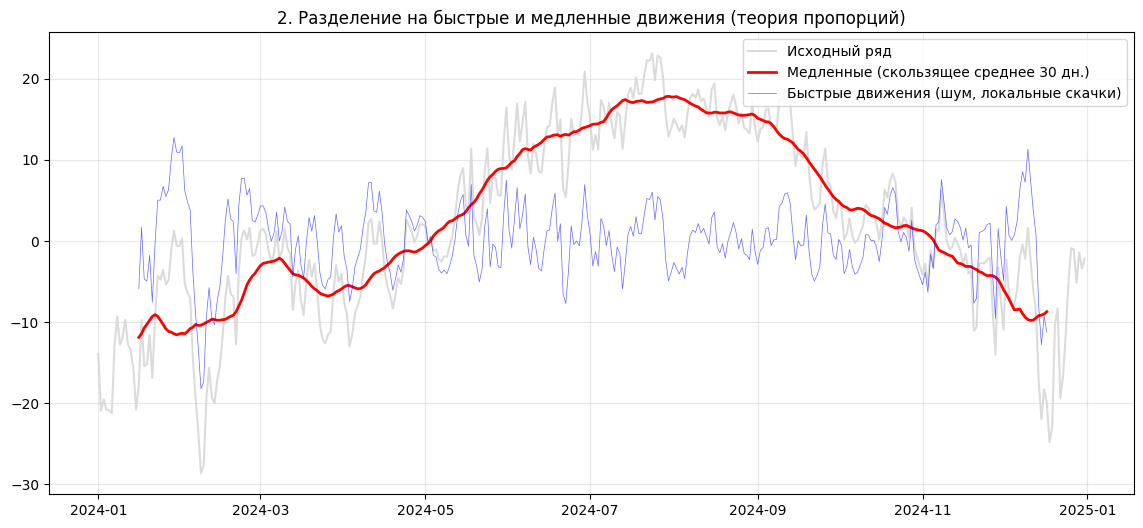

In [ ]:
window_size = 30  
ts_slow = ts.rolling(window=window_size, center=True).mean() 
ts_fast = ts - ts_slow 

plt.figure()
plt.plot(ts.index, ts.values, color='lightgray', label='Исходный ряд', alpha=0.8)
plt.plot(ts_slow.index, ts_slow.values, color='red', linewidth=2, label=f'Медленные (скользящее среднее {window_size} дн.)')
plt.plot(ts_fast.index, ts_fast.values, color='blue', linewidth=0.5, alpha=0.6, label='Быстрые движения (шум, локальные скачки)')
plt.title("2. Разделение на быстрые и медленные движения (теория пропорций)")
plt.legend(loc='upper right')
plt.show()

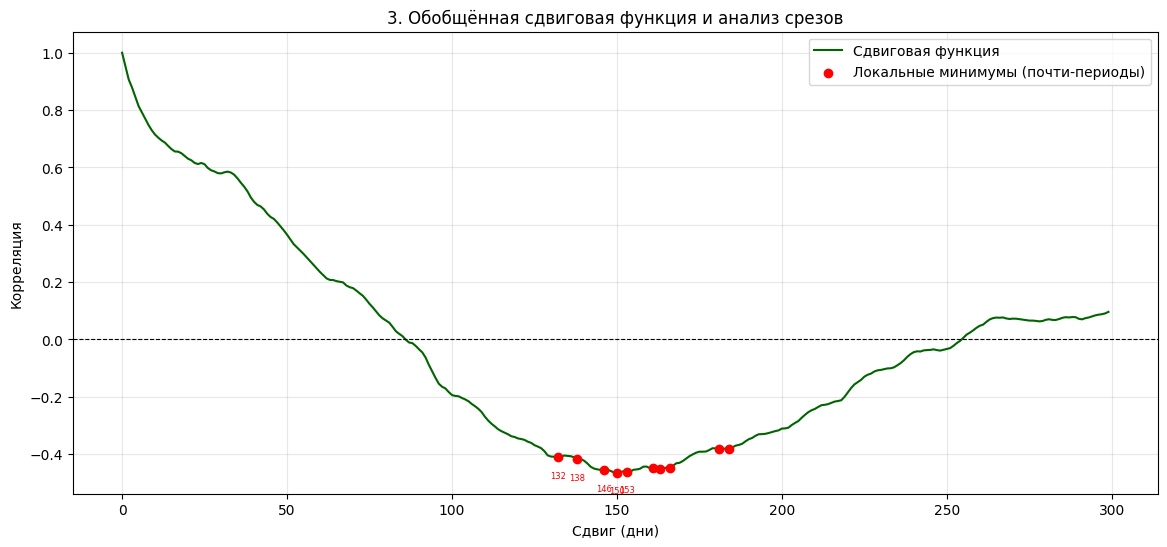

Найденные почти-периоды (сдвиги): [132 138 146 150 153] дней


In [ ]:
def generalized_shift_function(series, max_lag):
    n = len(series)
    mean = np.mean(series)
    variance = np.sum((series - mean)**2)
    shift_func = []
    for lag in range(max_lag):
        shifted = series[lag:]
        original = series[:n-lag]
        cov = np.sum((original - mean) * (shifted - mean))
        shift_func.append(cov / variance)
    return np.array(shift_func)

max_lag = 300
gsf = generalized_shift_function(ts.values, max_lag)

# поиск локальных минимумов (почти-периодов)
valleys, _ = find_peaks(-gsf, height=0.1) 

plt.figure()
plt.plot(range(max_lag), gsf, color='darkgreen', linewidth=1.5, label='Сдвиговая функция')
plt.scatter(valleys, gsf[valleys], color='red', zorder=5, label='Локальные минимумы (почти-периоды)')


for v in valleys[:5]: 
    plt.annotate(f'{v}', (v, gsf[v]), textcoords="offset points", xytext=(0,-15), ha='center', fontsize=6, color='red')

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title("3. Обобщённая сдвиговая функция и анализ срезов")
plt.xlabel("Сдвиг (дни)")
plt.ylabel("Корреляция")
plt.legend()
plt.show()

print(f"Найденные почти-периоды (сдвиги): {valleys[:5]} дней")

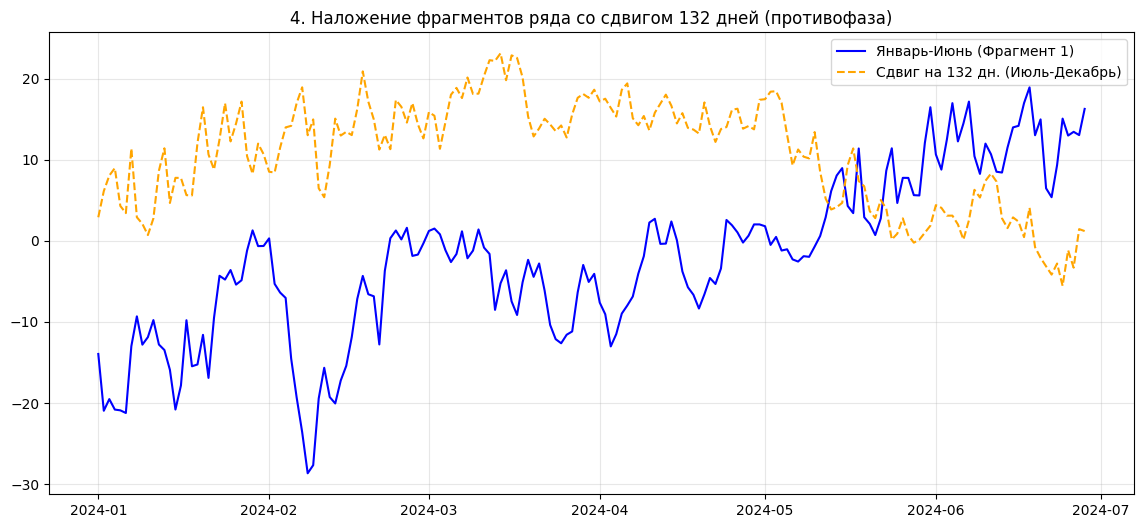

In [ ]:
if len(valleys) > 0:
    lag_demo = valleys[0]
    plt.figure()
    start = 0
    end = 180
    plt.plot(ts.index[start:end], ts.values[start:end], label='Январь-Июнь (Фрагмент 1)', color='blue')
    plt.plot(ts.index[start:end], ts.values[start+lag_demo : end+lag_demo], label=f'Сдвиг на {lag_demo} дн. (Июль-Декабрь)', color='orange', linestyle='--')
    plt.title(f"4. Наложение фрагментов ряда со сдвигом {lag_demo} дней (противофаза)")
    plt.legend()
    plt.show()

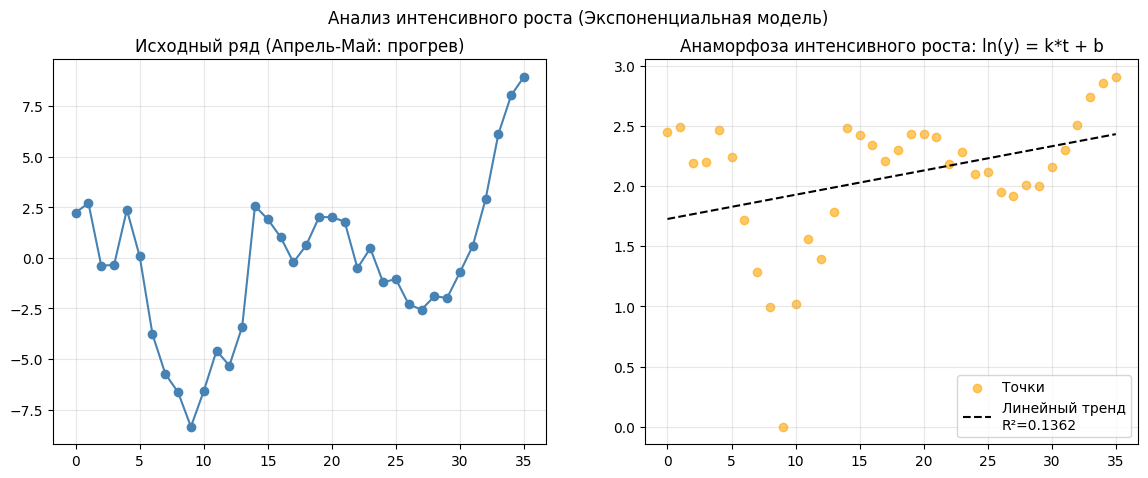

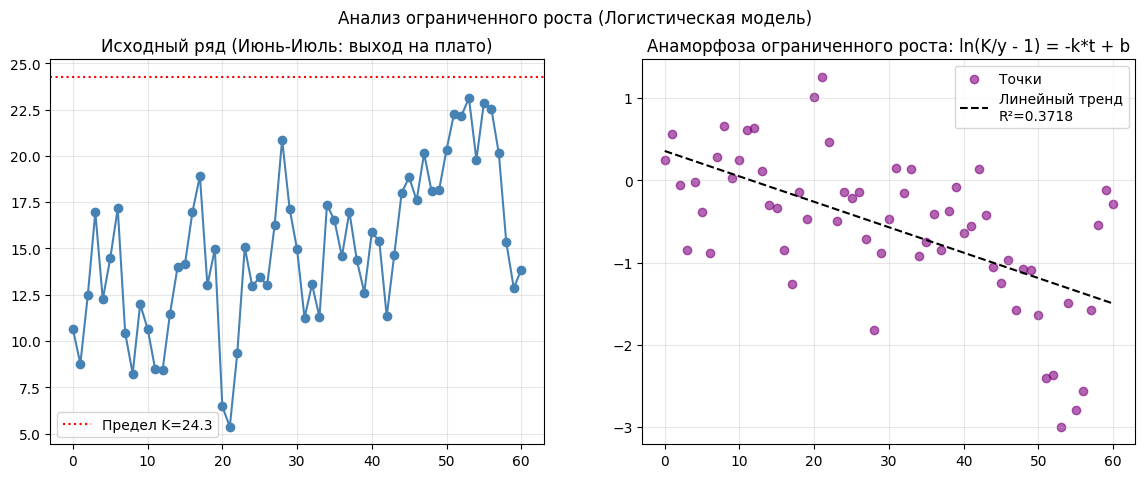

In [ ]:
intensive_period = ts['2024-04-10':'2024-05-15']
x_int = np.arange(len(intensive_period))
y_int_raw = intensive_period.values
y_int_shifted = y_int_raw - y_int_raw.min() + 1.0 
y_int_log = np.log(y_int_shifted)


slope_int, intercept_int, r_value_int, _, _ = linregress(x_int, y_int_log)
r2_int = r_value_int**2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(x_int, y_int_raw, 'o-', color='steelblue')
axes[0].set_title("Исходный ряд (Апрель-Май: прогрев)")

axes[1].scatter(x_int, y_int_log, color='orange', alpha=0.6, label='Точки')
axes[1].plot(x_int, slope_int * x_int + intercept_int, color='black', linestyle='--', label=f'Линейный тренд\nR²={r2_int:.4f}')
axes[1].set_title("Анаморфоза интенсивного роста: ln(y) = k*t + b")
axes[1].legend()
plt.suptitle("Анализ интенсивного роста (Экспоненциальная модель)")
plt.show()


limited_period = ts['2024-06-01':'2024-07-31']
x_lim = np.arange(len(limited_period))
y_lim_raw = limited_period.values
K = y_lim_raw.max() * 1.05 


y_lim_safe = np.clip(y_lim_raw, -50, K - 0.1) 
y_lim_anamorphosis = np.log(K / y_lim_safe - 1)

# Линейная регрессия
slope_lim, intercept_lim, r_value_lim, _, _ = linregress(x_lim, y_lim_anamorphosis)
r2_lim = r_value_lim**2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(x_lim, y_lim_raw, 'o-', color='steelblue')
axes[0].axhline(K, color='red', linestyle=':', label=f'Предел K={K:.1f}')
axes[0].set_title("Исходный ряд (Июнь-Июль: выход на плато)")
axes[0].legend()

axes[1].scatter(x_lim, y_lim_anamorphosis, color='purple', alpha=0.6, label='Точки')
axes[1].plot(x_lim, slope_lim * x_lim + intercept_lim, color='black', linestyle='--', label=f'Линейный тренд\nR²={r2_lim:.4f}')
axes[1].set_title("Анаморфоза ограниченного роста: ln(K/y - 1) = -k*t + b")
axes[1].legend()
plt.suptitle("Анализ ограниченного роста (Логистическая модель)")
plt.show()

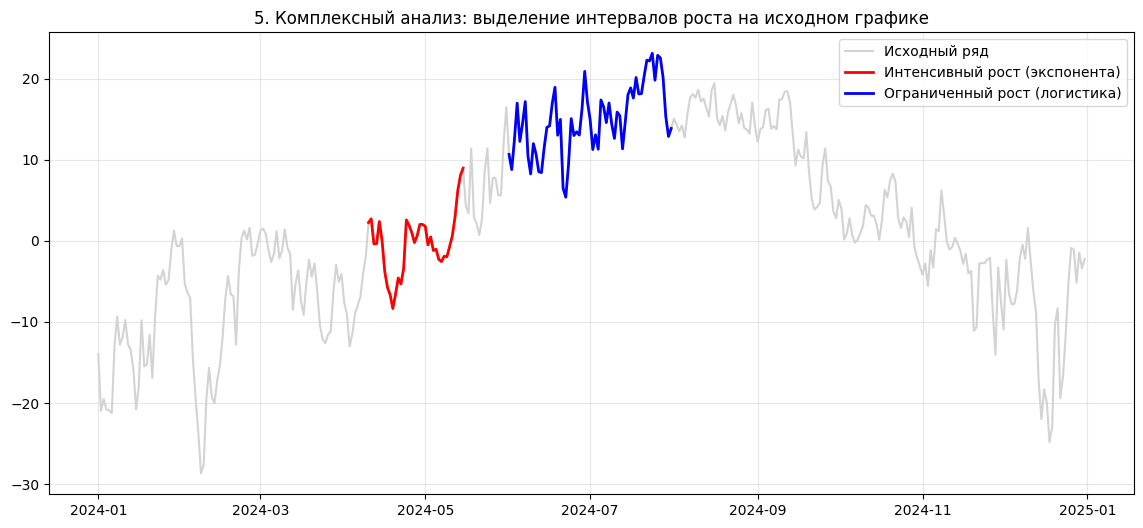

In [ ]:
plt.figure()
plt.plot(ts.index, ts.values, color='lightgray', label='Исходный ряд')


plt.plot(intensive_period.index, intensive_period.values, color='red', linewidth=2, label='Интенсивный рост (экспонента)')
plt.plot(limited_period.index, limited_period.values, color='blue', linewidth=2, label='Ограниченный рост (логистика)')

plt.title("5. Комплексный анализ: выделение интервалов роста на исходном графике")
plt.legend()
plt.show()